# 4.1: contexto de la adquisición

**Qué hace esta etapa.** Describe de dónde salen los datos con lo que muestran los archivos, no con lo que dice el esquema. Lo que se puede medir se mide; lo que solo dice la fuente (Penzel et al., 2000; la página de PhysioNet) se cita y se marca como tal. Tiene una parte que sí toca el pipeline: a 100 Hz el pico R cae en una grilla de 10 ms, y el refinamiento parabólico que corrige eso se usaba sin haberse verificado.

**Reglas (fijadas antes de correr).**
1. Todo con los 47 registros de desarrollo. De test solo se muestran las cuotas de categoría, que ya están en el plan de test (§1): el plan no permite describir sus etiquetas antes de abrirlo.
2. **Refinamiento del pico R, prueba de dos fases.** La señal del pipeline se baja a 50 Hz dos veces, con las muestras pares y con las impares (antes, un pasabajos a 22,5 Hz: el mismo ancho de banda relativo que 45 Hz a 100 Hz). Cada latido queda medido en dos grillas corridas 10 ms. Por sujeto se calcula la reducción del desacuerdo entre las dos (RMS sin refinar − RMS refinado). **Si el límite inferior del IC 95 % (bootstrap por sujeto) es > 0, el refinamiento se queda y el pipeline no cambia.** Si no, se saca, siempre que F sea no inferior sin él (δ = 0,02 en AUC por minuto y acierto por registro).
3. **AHI.** Se compara con la fracción de minutos de apnea, que es la referencia de M2, y se hace una vista previa de F y de la HRV contra el AHI. En el plan de test pasa a ser un resultado secundario.

In [1]:
import os
import sys
from concurrent.futures import ProcessPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.environ["PYTHONPATH"] = str(ROOT)
from src.config import ECG_FILTER, RESULTS_DIR, SPLIT_CSV
from src.data import load_ecg, load_ecg_digital, load_header, load_qrs, load_record_info
from src.features.build import record_feature_tables
from src.features.edr import qrs_reference
from src.preprocessing.filters import apply_zero_phase, design_bandpass
from src.preprocessing.quality import extreme_fraction, flat_mask, saturated_mask
from src.qrs.pan_tompkins import r_peaks_from_marks
from src.qrs.quantization import two_phase_peaks
from src.qrs.rr_clean import clean_rr
from src.stats.compare import agreement_compare, compare_variants

FIG = RESULTS_DIR / "figuras"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.8})
AZUL, NARANJA, GRIS, TINTA = "#2a78d6", "#eb6834", "#a3a29c", "#2b2b2b"
COLOR_CAT = {"A": NARANJA, "B": GRIS, "C": AZUL}
split = pd.read_csv(SPLIT_CSV).set_index("record")
DEV = list(split.index[split.set == "dev"])
info = load_record_info().set_index("record")
rng = np.random.default_rng(2026)

def boot_subjects(df, func, n=2000):
    # IC 95 % remuestreando sujetos con reposición; df tiene una columna "subject"
    groups = [g for _, g in df.groupby("subject")]
    vals = [func(pd.concat([groups[i] for i in rng.integers(0, len(groups), len(groups))]))
            for _ in range(n)]
    return np.nanpercentile(vals, [2.5, 97.5])

print(len(DEV), "registros de desarrollo,", split.loc[DEV, "subject"].nunique(), "sujetos | filtro:", ECG_FILTER)

47 registros de desarrollo, 19 sujetos | filtro: (0.5, 45.0, 3)


In [2]:
# Mediciones por registro que no usan etiquetas: formato, señal digital, calidad y picos R
filas, correcciones, fases, perdida_min = [], [], [], []
for rec in DEV:
    h = load_header(rec)
    d = load_ecg_digital(rec)
    ecg, fs = load_ecg(rec); qrs = load_qrs(rec)
    x = apply_zero_phase(ecg, design_bandpass(fs, *ECG_FILTER))
    off, sign = qrs_reference(x, qrs, fs)
    t_int, _ = r_peaks_from_marks(x, qrs, fs, off, sign, refine=False)
    t_ref, _ = r_peaks_from_marks(x, qrs, fs, off, sign)
    correcciones.append(1000 * (t_ref - t_int))
    _, _, corregidos = clean_rr(t_ref)
    tp = two_phase_peaks(x, qrs, fs, off, sign).assign(record=rec)
    fases.append(tp)
    perdida = flat_mask(d, fs)                       # tramos de 1 s o más sin cambio: señal perdida
    sat = saturated_mask(d, h["bits"])
    w = int(round(0.06 * fs)); c = qrs + off; c = c[(c >= w) & (c < len(d) - w)]
    qrs_sat = sat[c[:, None] + np.arange(-w, w + 1)].any(axis=1)   # ventana del área del EDR
    e = np.diff(np.r_[0, perdida.astype(np.int8), 0])
    largo = (np.flatnonzero(e == -1) - np.flatnonzero(e == 1)) / fs
    n_min = len(d) // 6000
    perdida_min.append(pd.DataFrame({"record": rec, "minute": np.arange(n_min),
                                     "perdida": perdida[: n_min * 6000].reshape(-1, 6000).mean(axis=1)}))
    filas.append({"record": rec, **h, "horas": h["muestras"] / h["fs"] / 3600,
                  "min_digital": int(d.min()), "max_digital": int(d.max()),
                  "muestras en los extremos": int(round(extreme_fraction(d) * len(d))),
                  "% señal perdida": 100 * perdida.mean(),
                  "tramo perdido más largo (s)": largo.max() if len(largo) else 0.0,
                  "% de lo saturado en tramos perdidos": 100 * (sat & perdida).sum() / max(sat.sum(), 1),
                  "% latidos con QRS saturado": 100 * qrs_sat.mean(), "% RR corregidos": 100 * corregidos.mean()})
med = pd.DataFrame(filas).set_index("record")
correcciones = np.concatenate(correcciones)
fases = pd.concat(fases, ignore_index=True)
print("listo:", len(med), "registros,", f"{len(correcciones):,}", "latidos")

listo: 47 registros, 1,553,494 latidos


## 1. Formato: lo que dicen los archivos

In [3]:
cols = ["fs", "formato", "ganancia", "bits", "cero", "unidad"]
print("Valores del encabezado (.hea) en los registros de desarrollo:")
for c in cols:
    print(f"  {c:9s}", dict(med[c].value_counts()))
lo, hi = -2 ** (med.bits.iloc[0] - 1), 2 ** (med.bits.iloc[0] - 1) - 1
print(f"\nRango digital observado: {med.min_digital.min()} a {med.max_digital.max()} "
      f"(un conversor de {med.bits.iloc[0]} bits va de {lo} a {hi}) -> "
      f"{'compatible' if med.min_digital.min() >= lo and med.max_digital.max() <= hi else 'NO compatible'} con el encabezado")
tope = med[(med.min_digital <= lo + 1) | (med.max_digital >= hi - 1)]
print(f"Registros que llegan al tope del conversor: {list(tope.index)}")
print(f"Resolución: {1000 / med.ganancia.iloc[0]:.0f} µV por paso | rango: ±{hi / med.ganancia.iloc[0]:.2f} mV | "
      f"tiempo: {1000 / med.fs.iloc[0]:.0f} ms por muestra")
print(f"Duración: {med.horas.min():.1f} a {med.horas.max():.1f} h (mediana {med.horas.median():.1f} h)")

Valores del encabezado (.hea) en los registros de desarrollo:
  fs        {100.0: np.int64(47)}
  formato   {'16': np.int64(47)}
  ganancia  {200.0: np.int64(47)}
  bits      {12: np.int64(47)}
  cero      {0: np.int64(47)}
  unidad    {'mV': np.int64(47)}

Rango digital observado: -2048 a 2047 (un conversor de 12 bits va de -2048 a 2047) -> compatible con el encabezado
Registros que llegan al tope del conversor: ['a03', 'a05', 'a08', 'a10', 'a15', 'a17', 'a19', 'a20', 'b02', 'c01', 'c02', 'c09', 'c10', 'x04', 'x05', 'x07', 'x08', 'x10', 'x12', 'x14', 'x16', 'x17', 'x18', 'x20', 'x21', 'x27', 'x28', 'x35']
Resolución: 5 µV por paso | rango: ±10.23 mV | tiempo: 10 ms por muestra
Duración: 6.8 a 9.6 h (mediana 8.3 h)


**Qué se verifica y qué se cita.**

| Afirmación | Fuente |
|---|---|
| 100 Hz, ganancia 200 por mV, conversor de 12 bits guardado en formato 16 | **medido** (encabezado y rango de valores, arriba). El esquema v2 decía "16 bits": el 16 es el formato del archivo, no la resolución |
| Una etiqueta de apnea o normal por minuto | **medido** (archivos `.apn`, sección 2) |
| Las etiquetas las puso un experto a partir de la polisomnografía (respiración, saturación y otras señales) | **citado** (Penzel et al., 2000) |
| Las marcas `.qrs` son automáticas y no están auditadas | **citado** (PhysioNet); su calidad se mide en 4.3 |
| Derivación del ECG | **citado**: el archivo solo dice "ECG" |

## 2. Los registros de desarrollo

La **categoría** sale de los minutos con apnea (A ≥ 100, B 5–99, C < 5). El **AHI** (apneas e hipopneas por hora de sueño) viene de la base, de la polisomnografía. La primera cuenta minutos; el segundo, eventos.

In [4]:
dev = split.loc[DEV, ["subject", "category", "n_minutes", "apnea_minutes"]].join(info[["AI", "HI", "AHI", "age", "sex"]])
dev["horas"] = med.horas
dev["% apnea"] = 100 * dev.apnea_minutes / dev.n_minutes
resumen = dev.groupby("category").agg(registros=("subject", "size"), sujetos=("subject", "nunique"),
                                      horas=("horas", "median"),
                                      pct_apnea_mediana=("% apnea", "median"),
                                      pct_apnea_min=("% apnea", "min"), pct_apnea_max=("% apnea", "max"),
                                      AHI_mediana=("AHI", "median"), AHI_min=("AHI", "min"), AHI_max=("AHI", "max"))
display(resumen.round(1))
print(f"minutos con etiqueta: {dev.n_minutes.sum():,} | con apnea: {dev.apnea_minutes.sum() / dev.n_minutes.sum():.1%}")
print("\nCuotas de categoría por conjunto (las del plan de test, §1):")
display(split.groupby(["set", "category"]).size().unstack())

,registros,sujetos,horas,pct_apnea_mediana,pct_apnea_min,pct_apnea_max,AHI_mediana,AHI_min,AHI_max
category,,,,,,,,,
A,28,12,8.4,62.2,19.3,97.8,42.5,14.3,82.4
B,7,4,8.5,12.6,2.6,18.8,19.0,0.1,33.0
C,12,5,7.8,0.2,0.0,0.9,0.0,0.0,0.4


minutos con etiqueta: 23,138 | con apnea: 39.8%

Cuotas de categoría por conjunto (las del plan de test, §1):


category,A,B,C
set,,,
dev,28,7,12
test,12,3,5


Spearman entre % de minutos con apnea y AHI: 0.944 (IC 0.841 a 0.968), 47 registros

Categoría por minutos contra gravedad clínica por AHI:


AHI,normal (< 5),leve (5-15),moderada (15-30),grave (≥ 30)
category,,,,
A,0,1,4,23
B,2,1,3,1
C,12,0,0,0


Registros donde más difieren los dos órdenes:


,category,apnea_minutes,% apnea,AI,HI,AHI
record,,,,,,
a09,A,381,76.97,23.1,8.60,31.70
x12,B,57,10.82,21.0,12.00,33.00
a08,A,189,37.72,32.0,10.00,42.00
c06,C,1,0.21,0.0,0.25,0.25
x09,A,167,32.87,1.8,16.70,18.50
x07,A,240,47.15,11.0,10.00,21.00


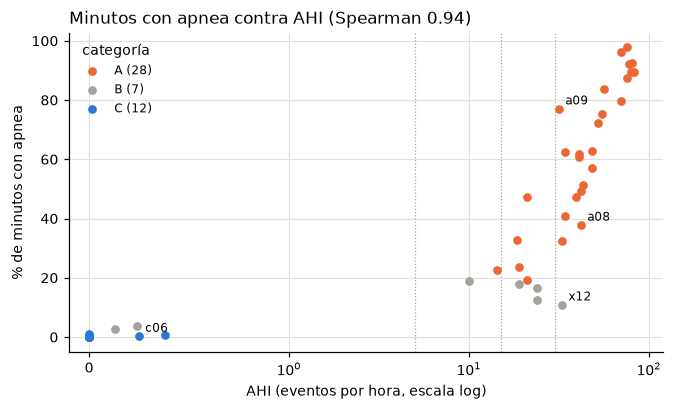

In [5]:
r_frac = spearmanr(dev["% apnea"], dev.AHI)[0]
ci = boot_subjects(dev, lambda g: spearmanr(g["% apnea"], g.AHI)[0])
print(f"Spearman entre % de minutos con apnea y AHI: {r_frac:.3f} (IC {ci[0]:.3f} a {ci[1]:.3f}), {len(dev)} registros")

grav = pd.cut(dev.AHI, [-np.inf, 5, 15, 30, np.inf], right=False,
              labels=["normal (< 5)", "leve (5-15)", "moderada (15-30)", "grave (≥ 30)"])
print("\nCategoría por minutos contra gravedad clínica por AHI:")
display(pd.crosstab(dev.category, grav))

rk = (dev["% apnea"].rank() - dev.AHI.rank()).abs().sort_values(ascending=False)
print("Registros donde más difieren los dos órdenes:")
display(dev.loc[rk.index[:6], ["category", "apnea_minutes", "% apnea", "AI", "HI", "AHI"]].round(2))

fig, ax = plt.subplots(figsize=(6.2, 3.8))
for c, g in dev.groupby("category"):
    ax.scatter(g.AHI, g["% apnea"], s=22, color=COLOR_CAT[c], label=f"{c} ({len(g)})", zorder=3)
for rec in rk.index[:4]:
    ax.annotate(rec, (dev.AHI[rec], dev["% apnea"][rec]), xytext=(4, 3), textcoords="offset points", fontsize=8)
for v in (5, 15, 30):
    ax.axvline(v, color=GRIS, lw=0.8, ls=":")
ax.set_xscale("symlog", linthresh=1); ax.set_xlim(-0.1, 120)
ax.set_xlabel("AHI (eventos por hora, escala log)"); ax.set_ylabel("% de minutos con apnea")
ax.set_title(f"Minutos con apnea contra AHI (Spearman {r_frac:.2f})", loc="left"); ax.legend(frameon=False, fontsize=8, title="categoría")
fig.tight_layout(); fig.savefig(FIG / "adq_ahi.png")

## 3. Calidad por registro

Se calculan una vez las features del pipeline (F y la HRV de referencia) con y sin refinamiento; se usan acá (calidad por minuto) y en la sección 4.

In [6]:
B = {"ap": (0.01, 0.05)}
n = len(DEV)
tabs = {}
with ProcessPoolExecutor(max_workers=max(1, (os.cpu_count() or 2) - 1)) as ex:
    for refine in (True, False):
        res = list(ex.map(record_feature_tables, DEV, [(180, 240)] * n, [("welch3",)] * n, [("area",)] * n,
                          [B] * n, [ROOT / "data" / "raw"] * n, [refine] * n))
        tabs[refine] = (pd.concat([r[0] for r in res], ignore_index=True),
                        pd.concat([r[1] for r in res], ignore_index=True))
coup = tabs[True][0]
m240 = coup[(coup.window == 240) & (coup.label >= 0)].copy()
m240["excluido"] = ~(m240.corrected <= 0.2)        # un minuto sin latidos también queda afuera
cal = med[["muestras en los extremos", "% señal perdida", "% RR corregidos"]].copy()
cal["% minutos excluidos"] = 100 * m240.groupby("record").excluido.mean()
cal = cal.join(dev[["category"]])
print("Por registro (mediana [mín - máx]):")
for c in ["muestras en los extremos", "% señal perdida", "% RR corregidos", "% minutos excluidos"]:
    print(f"  {c:26s} {cal[c].median():8.2f}  [{cal[c].min():.2f} - {cal[c].max():.2f}]")
print("\nLos 6 registros con más minutos excluidos:")
display(cal.sort_values("% minutos excluidos", ascending=False).head(6).round(2))
cal["% en los extremos"] = 100 * cal["muestras en los extremos"] / med.muestras
print("Los 5 registros con más muestras en los extremos (saturación):")
display(cal.sort_values("muestras en los extremos", ascending=False).head(5)
        [["muestras en los extremos", "% en los extremos", "% minutos excluidos", "category"]].round(2))
s = med[med["muestras en los extremos"] > 100]
print(f"Cómo es la saturación, en los {len(s)} registros con más de 100 muestras en el tope "
      f"(mediana [mín - máx]):")
for c in ["% de lo saturado en tramos perdidos", "tramo perdido más largo (s)", "% latidos con QRS saturado"]:
    print(f"  {c:36s} {s[c].median():7.2f}  [{s[c].min():.2f} - {s[c].max():.2f}]")

Por registro (mediana [mín - máx]):
  muestras en los extremos      10.00  [2.00 - 83665.00]
  % señal perdida                0.02  [0.00 - 2.68]
  % RR corregidos                0.56  [0.03 - 13.47]
  % minutos excluidos            0.20  [0.00 - 40.87]

Los 6 registros con más minutos excluidos:


,muestras en los extremos,% señal perdida,% RR corregidos,% minutos excluidos,category
record,,,,,
a02,2,0.01,13.23,40.87,A
x17,168,0.68,13.47,27.39,C
x25,2,0.00,8.55,8.71,A
x14,43,1.57,3.95,8.61,A
a12,2,0.01,4.58,7.68,A
c03,2,0.02,7.64,7.57,C


Los 5 registros con más muestras en los extremos (saturación):


,muestras en los extremos,% en los extremos,% minutos excluidos,category
record,,,,
x20,83665,2.72,7.48,A
x12,49475,1.54,0.00,B
b02,34117,1.08,3.69,B
a17,32382,1.11,2.08,A
x28,3990,0.13,0.21,A


Cómo es la saturación, en los 14 registros con más de 100 muestras en el tope (mediana [mín - máx]):
  % de lo saturado en tramos perdidos    80.04  [0.00 - 100.00]
  tramo perdido más largo (s)             6.08  [1.04 - 244.87]
  % latidos con QRS saturado              0.03  [0.00 - 0.23]


minutos excluidos: con apnea 3.5% | normales 2.3% | diferencia +1.2 puntos (IC -2.8 a +6.8)


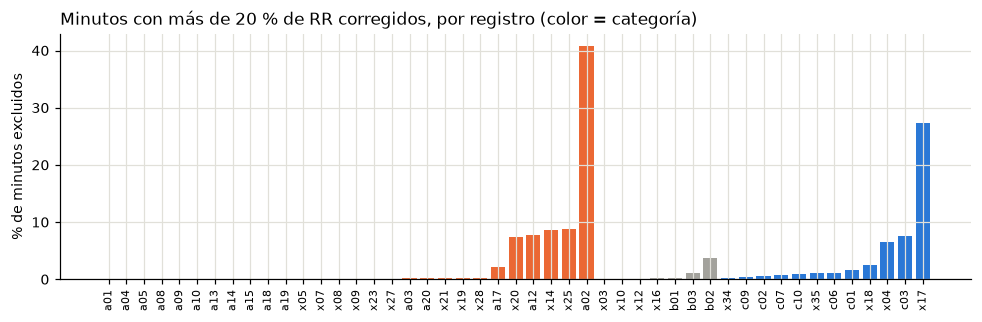

In [7]:
# ¿La regla del 20 % saca más minutos de apnea que normales? (relevante para la política de minutos malos, antes de congelar)
m240 = m240.join(split.subject, on="record")
por_clase = m240.groupby("label").excluido.mean()
dif = lambda g: g[g.label == 1].excluido.mean() - g[g.label == 0].excluido.mean()
ci = boot_subjects(m240, dif)
print(f"minutos excluidos: con apnea {por_clase[1]:.1%} | normales {por_clase[0]:.1%} | "
      f"diferencia {100 * dif(m240):+.1f} puntos (IC {100 * ci[0]:+.1f} a {100 * ci[1]:+.1f})")

fig, ax = plt.subplots(figsize=(9, 3))
o = cal.sort_values(["category", "% minutos excluidos"])
ax.bar(range(len(o)), o["% minutos excluidos"], color=[COLOR_CAT[c] for c in o.category])
ax.set_xticks(range(len(o)), o.index, rotation=90, fontsize=7)
ax.set_ylabel("% de minutos excluidos"); ax.set_title("Minutos con más de 20 % de RR corregidos, por registro (color = categoría)", loc="left")
fig.tight_layout(); fig.savefig(FIG / "adq_calidad.png")

In [8]:
# ¿La regla del 20 % ve los minutos con señal perdida?
pm = pd.concat(perdida_min).set_index(["record", "minute"])
mm = m240.set_index(["record", "minute"]).join(pm)
for umbral, nombre in ((0, "con alguna señal perdida"), (0.5, "con más de la mitad perdida")):
    sel = mm.perdida > umbral
    print(f"minutos {nombre}: {int(sel.sum())} ({sel.mean():.2%}) | la regla del 20 % excluye {mm.excluido[sel].mean():.0%}")
p_clase = mm.groupby("label").perdida.apply(lambda v: (v > 0).mean())
d2 = lambda g: (g[g.label == 1].perdida > 0).mean() - (g[g.label == 0].perdida > 0).mean()
ci = boot_subjects(mm.reset_index(), d2)
print(f"minutos con alguna señal perdida: con apnea {p_clase[1]:.2%} | normales {p_clase[0]:.2%} | "
      f"diferencia {100 * d2(mm):+.2f} puntos (IC {100 * ci[0]:+.2f} a {100 * ci[1]:+.2f})")

minutos con alguna señal perdida: 91 (0.40%) | la regla del 20 % excluye 56%
minutos con más de la mitad perdida: 50 (0.22%) | la regla del 20 % excluye 90%


minutos con alguna señal perdida: con apnea 0.35% | normales 0.43% | diferencia -0.08 puntos (IC -0.39 a +0.24)


## 4. Cuantización a 10 ms

### a. Tamaño del problema

Si el pico real cae en cualquier punto entre dos muestras, el error de tomar la muestra más cercana es uniforme en ±5 ms: desvío 10/√12 = 2,9 ms. En la diferencia entre dos RR sucesivos entran tres picos (t₃ − 2t₂ + t₁), así que el desvío sube a √6 × 2,9 = 7,1 ms, y eso infla el RMSSD.

Corrección del refinamiento a 100 Hz (refinado - muestra entera): desvío 2.65 ms (uniforme en ±5 ms: 2.89) | |corrección| máx 5.0 ms | 1,553,494 latidos


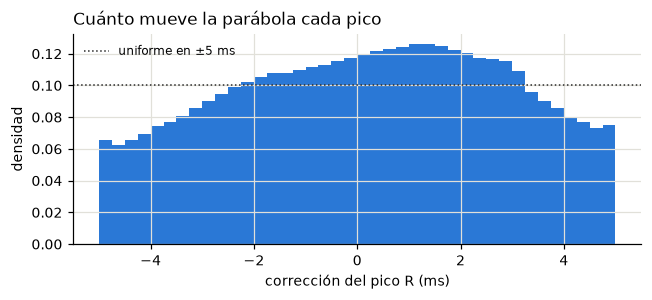

In [9]:
print(f"Corrección del refinamiento a 100 Hz (refinado - muestra entera): desvío {correcciones.std():.2f} ms "
      f"(uniforme en ±5 ms: {10 / np.sqrt(12):.2f}) | |corrección| máx {np.abs(correcciones).max():.1f} ms | "
      f"{len(correcciones):,} latidos")
fig, ax = plt.subplots(figsize=(6, 2.8))
ax.hist(correcciones, bins=np.linspace(-5, 5, 41), color=AZUL, density=True)
ax.axhline(1 / 10, color=TINTA, lw=1, ls=":", label="uniforme en ±5 ms")
ax.set_xlabel("corrección del pico R (ms)"); ax.set_ylabel("densidad")
ax.set_title("Cuánto mueve la parábola cada pico", loc="left"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "adq_correccion.png")

### b. ¿La parábola recupera el tiempo real? Prueba de dos fases a 50 Hz

latidos donde las dos fases encuentran el mismo pico: 99.95%
desacuerdo entre fases (RMS, media por sujeto): sin refinar 10.00 ms | refinado 2.52 ms
reducción 7.48 ms (IC 7.39 a 7.58), 19 sujetos; reduce en 19 de 19
error estimado de cada fase a 50 Hz: sin refinar 7.1 ms | refinado 1.8 ms
-> regla: el refinamiento se queda


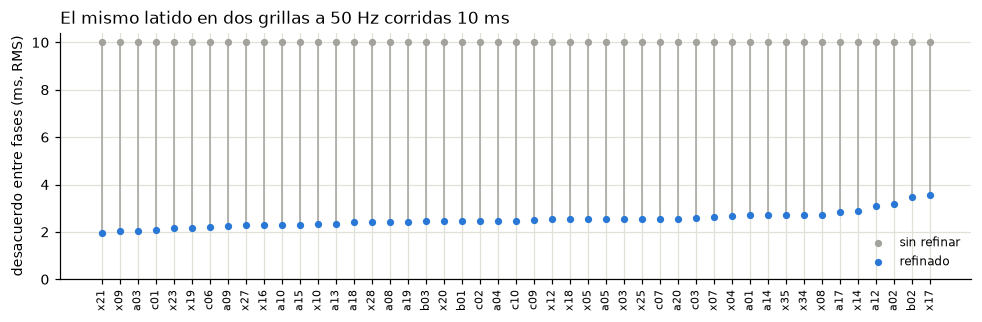

In [10]:
fases["sin refinar"] = 1000 * (fases.par - fases.impar)
fases["refinado"] = 1000 * (fases.par_ref - fases.impar_ref)
fases["ok"] = fases["sin refinar"].abs() <= 20          # las dos fases encontraron el mismo pico
rms = lambda v: float(np.sqrt(np.mean(np.square(v))))
ok = fases[fases.ok]
por_reg = ok.groupby("record")[["sin refinar", "refinado"]].agg(rms).join(split.subject)
por_suj = por_reg.groupby("subject")[["sin refinar", "refinado"]].mean()
red = por_suj["sin refinar"] - por_suj["refinado"]
b = rng.choice(red.to_numpy(), size=(5000, len(red))).mean(axis=1)
RED_LO, RED_HI = np.percentile(b, [2.5, 97.5])
print(f"latidos donde las dos fases encuentran el mismo pico: {fases.ok.mean():.2%}")
print(f"desacuerdo entre fases (RMS, media por sujeto): sin refinar {por_suj['sin refinar'].mean():.2f} ms | "
      f"refinado {por_suj['refinado'].mean():.2f} ms")
print(f"reducción {red.mean():.2f} ms (IC {RED_LO:.2f} a {RED_HI:.2f}), {len(red)} sujetos; "
      f"reduce en {int((red > 0).sum())} de {len(red)}")
print(f"error estimado de cada fase a 50 Hz: sin refinar {por_suj['sin refinar'].mean() / np.sqrt(2):.1f} ms | "
      f"refinado {por_suj['refinado'].mean() / np.sqrt(2):.1f} ms")
print(f"-> regla: {'el refinamiento se queda' if RED_LO > 0 else 'el refinamiento no reduce el error: verificar F sin él'}")

fig, ax = plt.subplots(figsize=(9, 3))
o = por_reg.sort_values("refinado")
ax.vlines(range(len(o)), o.refinado, o["sin refinar"], color=GRIS, lw=1)
ax.scatter(range(len(o)), o["sin refinar"], color=GRIS, s=14, label="sin refinar", zorder=3)
ax.scatter(range(len(o)), o.refinado, color=AZUL, s=14, label="refinado", zorder=3)
ax.set_xticks(range(len(o)), o.index, rotation=90, fontsize=7); ax.set_ylim(0, None)
ax.set_ylabel("desacuerdo entre fases (ms, RMS)")
ax.set_title("El mismo latido en dos grillas a 50 Hz corridas 10 ms", loc="left"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "adq_dos_fases.png")

### c. ¿Le importa al pipeline?

F (potencia cruzada RR–EDR en 0,01–0,05 Hz, 240 s) y la HRV de referencia (VLF por Lomb, 180 s), con y sin refinamiento, sobre los mismos minutos de evaluación de E3a. Además, RMSSD y pNN50 (no están en el pipeline, pero la consigna pide HRV y son las que más sufre la cuantización).

In [11]:
CACHE = RESULTS_DIR / "e3"
from src.features.variants import coupling_variants, hrv_variants
c3 = pd.read_parquet(CACHE / "acoplamiento.parquet"); h3 = pd.read_parquet(CACHE / "hrv.parquet")
wc, _ = coupling_variants(c3); wh, _ = hrv_variants(h3)
inf3 = (c3[(c3.edr == "area") & (c3.window == 512) & (c3.estimator == "welch3")]
        .set_index(["record", "minute"])[["label", "corrected"]])
idx = wc.dropna().index.intersection(wh.dropna().index).intersection(
    inf3.index[(inf3.label >= 0) & (inf3.corrected <= 0.2)])
del c3, h3, wc, wh

def feats(refine):
    c, h = tabs[refine]
    c = c[c.window == 240].set_index(["record", "minute"]); h = h[h.window == 180].set_index(["record", "minute"])
    return pd.DataFrame({"F": np.log(np.maximum(c.xp_ap.reindex(idx), 1e-12)), "HRV": h.vlf.reindex(idx),
                         "rmssd": h.rmssd.reindex(idx), "pnn50": h.pnn50.reindex(idx)})
con, sin = feats(True), feats(False)
ok_m = con.notna().all(axis=1) & sin.notna().all(axis=1)
con, sin = con[ok_m], sin[ok_m]
y = inf3.loc[con.index, "label"].to_numpy().astype(int)
recs = con.index.get_level_values("record").to_numpy(); subj = split.loc[recs, "subject"].to_numpy()
print(f"minutos: {len(con):,} de {len(idx):,} de E3a")

tablas = {}
for f in ("F", "HRV"):
    T = pd.DataFrame({f"{f} con refinamiento": con[f], f"{f} sin refinamiento": sin[f]})
    a = compare_variants(T, y, subj, n_boot=2000); g = agreement_compare(T, y, recs, subj, n_boot=2000)
    tablas[f] = (a, g)
    display(a[["auc", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3))
    display(g[["spearman", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3))

minutos: 22,123 de 22,123 de E3a


,auc,ic_lo,ic_hi,dif,dif_lo,dif_hi
F con refinamiento,0.875,0.809,0.925,0.0,0.0,0.0
F sin refinamiento,0.875,0.809,0.925,-0.0,-0.0,0.0


,spearman,ic_lo,ic_hi,dif,dif_lo,dif_hi
F con refinamiento,0.810,0.556,0.935,-0.002,-0.017,0.003
F sin refinamiento,0.813,0.560,0.935,0.000,0.000,0.000


,auc,ic_lo,ic_hi,dif,dif_lo,dif_hi
HRV con refinamiento,0.81,0.703,0.893,0.0,0.0,0.0
HRV sin refinamiento,0.81,0.702,0.892,-0.0,-0.0,-0.0


,spearman,ic_lo,ic_hi,dif,dif_lo,dif_hi
HRV con refinamiento,0.415,-0.102,0.787,-0.001,-0.008,0.007
HRV sin refinamiento,0.417,-0.100,0.789,0.000,0.000,0.000


In [12]:
r_con, r_sin = 1000 * con.rmssd, 1000 * sin.rmssd
exceso = (r_sin ** 2 - r_con ** 2)
print(f"RMSSD por minuto (mediana): con refinamiento {r_con.median():.1f} ms | sin {r_sin.median():.1f} ms | "
      f"sube {100 * (r_sin / r_con - 1).median():.0f} % (mediana por minuto)")
print(f"exceso de varianza sin refinar (RMSSD² sin - con, mediana): {exceso.median():.0f} ms² | "
      f"teoría para error uniforme: 6 × 10²/12 = {6 * 100 / 12:.0f} ms²")
print(f"pNN50 por minuto (media): con {con.pnn50.mean():.3f} | sin {sin.pnn50.mean():.3f}")
q = pd.qcut(r_con, 4)
print("\nSuba del RMSSD según el RMSSD del minuto (cuartiles):")
display((100 * (r_sin / r_con - 1)).groupby(q, observed=True).median().round(1).rename("% de suba (mediana)"))

RMSSD por minuto (mediana): con refinamiento 24.6 ms | sin 25.5 ms | sube 4 % (mediana por minuto)
exceso de varianza sin refinar (RMSSD² sin - con, mediana): 46 ms² | teoría para error uniforme: 6 × 10²/12 = 50 ms²
pNN50 por minuto (media): con 0.120 | sin 0.122

Suba del RMSSD según el RMSSD del minuto (cuartiles):


rmssd
(3.761, 16.844]      13.1
(16.844, 24.553]      5.5
(24.553, 40.848]      2.3
(40.848, 161.107]     0.6
Name: % de suba (mediana), dtype: float64

## 5. Vista previa: F y la HRV contra el AHI

Solo descriptivo y optimista: desarrollo se usó para elegir F y la HRV. Se compara el acierto por registro contra las dos referencias, la fracción de minutos con apnea (la de M2) y el AHI de la base.

In [13]:
T = pd.DataFrame({"F": con.F, "HRV": con.HRV})
ahi = info.AHI
for nombre, ref in (("fracción de minutos con apnea", None), ("AHI", ahi)):
    g = agreement_compare(T, y, recs, subj, n_boot=2000, reference=ref)
    print(f"Contra {nombre}:")
    display(g[["spearman", "ic_lo", "ic_hi", "dif", "dif_lo", "dif_hi"]].round(3))

Contra fracción de minutos con apnea:


,spearman,ic_lo,ic_hi,dif,dif_lo,dif_hi
F,0.810,0.556,0.935,0.000,0.000,0.000
HRV,0.415,-0.102,0.787,-0.395,-0.779,-0.074


Contra AHI:


,spearman,ic_lo,ic_hi,dif,dif_lo,dif_hi
F,0.781,0.497,0.915,0.000,0.000,0.000
HRV,0.395,-0.091,0.768,-0.386,-0.762,-0.074


## Decisión

**El pipeline no cambia: el refinamiento parabólico del pico R se queda.**

- **Formato (medido).** Los 47 registros tienen 100 Hz, ganancia de 200 unidades por mV (5 µV por paso) y un conversor de **12 bits**, guardado en formato de 16 bits. Los valores van de −2048 a 2047, lo que confirma los 12 bits. El esquema v2 decía "16 bits": se corrige.
- **Saturación: es señal perdida, no un QRS recortado.** 28 de los 47 registros llegan al tope del conversor (±10,2 mV) alguna vez, casi siempre con pocas muestras (mediana de 10 por registro). Cuatro pasan del 1 %: x20 (2,7 %), x12 (1,5 %), b02 y a17 (1,1 %). En los 14 registros con más de 100 muestras en el tope, la mediana del 80 % de lo saturado está en tramos de 1 s o más clavados ahí (el más largo, 245 s), y solo el 0,03 % de los latidos tiene el QRS saturado (máximo 0,23 %). En esos tramos no hay ECG, y el RR y el EDR se interpolan a través del hueco. 91 minutos (0,4 %) tienen algo de señal perdida; la regla del 20 % excluye el 56 % y los otros 40 pasan. No se asocia con la apnea: 0,35 % de los minutos con apnea contra 0,43 % de los normales (IC −0,39 a +0,24 puntos).
- **Dataset.** 28 registros A, 7 B y 12 C, de 19 sujetos; de 6,8 a 9,6 h; 23.138 minutos con etiqueta, 39,8 % con apnea.
- **Minutos con apnea y AHI.** Spearman 0,94 (IC 0,84 a 0,97): ordenan las noches casi igual. La categoría B es la que menos coincide con la gravedad clínica: sus 7 registros van de un AHI de 0,1 a 33.
- **Regla del 20 % de RR corregidos.** La mediana por registro excluye el 0,2 % de los minutos, pero a02 pierde el 41 % y x17 el 27 %. Saca algo más de minutos con apnea que normales (3,5 % contra 2,3 %), sin diferencia significativa (IC −2,8 a +6,8 puntos). Esta regla también se había asumido. Queda descrita acá. Qué hacer con los minutos malos (esta regla y la saturación) se decide antes de congelar, en la etapa de umbrales (§5 del esquema v2). Como la regla está fijada en el plan de test (§4, minutos que se evalúan), si cambia se registra ahí como desvío.
- **Cuantización.** La parábola mueve cada pico con un desvío de 2,65 ms, cerca de los 2,9 ms de un error uniforme en ±5 ms. En la prueba de dos fases baja el desacuerdo de 10,0 a 2,5 ms, en los 19 sujetos (reducción de 7,5 ms, IC 7,4 a 7,6): recupera el tiempo entre muestras. **Por la regla fijada, se queda.**
- **Efecto en el pipeline: nulo en F y en la HRV de referencia.** AUC 0,875 y 0,81 con y sin refinamiento, y acierto por registro con diferencias de 0,003 o menos. Las dos miran 0,01 a 0,05 Hz y el error de cuantización cambia latido a latido, así que casi no tiene potencia en esa banda. Donde sí importa es en el RMSSD: sin refinar sube un 4 % (mediana) y un 13 % en los minutos de RMSSD más bajo. El exceso de varianza (46 ms²) coincide con la teoría (50 ms²). El pNN50 casi no cambia.
- **Vista previa contra el AHI (optimista).** F 0,78 contra HRV 0,40, diferencia −0,39 (IC −0,76 a −0,07). Es el mismo cuadro que contra la fracción de minutos (0,81 contra 0,42). En el plan de test el AHI pasa a ser un resultado secundario.